In [3]:
import pandas as pd
import numpy as np


In [4]:
# can we have multiple index? Let's try
index_val = [('cse',2019),('cse',2020),('cse',2021),('cse',2022),('ece',2019),('ece',2020),('ece',2021),('ece',2022)]
a = pd.Series([1,2,3,4,5,6,7,8],index=index_val)
a
# Here in index_val branch and year are depended on each other
# we have to do lots of work to get value for only index ='cse'

(cse, 2019)    1
(cse, 2020)    2
(cse, 2021)    3
(cse, 2022)    4
(ece, 2019)    5
(ece, 2020)    6
(ece, 2021)    7
(ece, 2022)    8
dtype: int64

In [5]:
# The solution -> multiindex series(also known as Hierarchical Indexing) is to create a multiindex object
# How to create a multiindex object
# 1. pd.MultiIndex.from_tuples()
index_val = [('cse',2019),('cse',2020),('cse',2021),('cse',2022),('ece',2019),('ece',2020),('ece',2021),('ece',2022)]
multiindex = pd.MultiIndex.from_tuples(index_val)
print(multiindex)
print(multiindex.levels)
print(multiindex.levels[0])
# 2. pd.MultiIndex.from_product() 
pd.MultiIndex.from_product([['cse','ece'],[2019,2020,2021,2022]])

MultiIndex([('cse', 2019),
            ('cse', 2020),
            ('cse', 2021),
            ('cse', 2022),
            ('ece', 2019),
            ('ece', 2020),
            ('ece', 2021),
            ('ece', 2022)],
           )
[['cse', 'ece'], [2019, 2020, 2021, 2022]]
Index(['cse', 'ece'], dtype='object')


MultiIndex([('cse', 2019),
            ('cse', 2020),
            ('cse', 2021),
            ('cse', 2022),
            ('ece', 2019),
            ('ece', 2020),
            ('ece', 2021),
            ('ece', 2022)],
           )

In [6]:
# create a series with multiindex object
s = pd.Series([1,2,3,4,5,6,7,8],index=multiindex)
print(s)
# how to fetch items from such a series
print("Number =",s[('cse',2022)])
print(s['cse'])

# Dimension of multiindex series = 2-D
# ya data toa hum dataframe mai store kr skta hai because dataframe is also 2-D
# so hum multiindex series kyu use krta hai ??
# multiindex series ka use kr k hum Higer dimension data [10-d. etc] koa lower
# dimension[eg dataframe,series] mai represent kr skta hai..

cse  2019    1
     2020    2
     2021    3
     2022    4
ece  2019    5
     2020    6
     2021    7
     2022    8
dtype: int64
Number = 4
2019    1
2020    2
2021    3
2022    4
dtype: int64


     2019  2020  2021  2022
cse     1     2     3     4
ece     5     6     7     8
cse  2019    1
     2020    2
     2021    3
     2022    4
ece  2019    5
     2020    6
     2021    7
     2022    8
dtype: int64


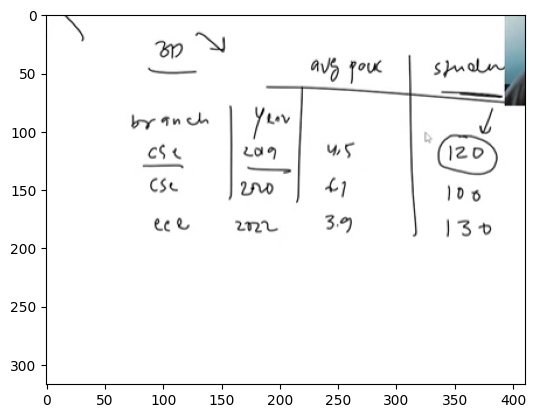

In [7]:
# unstack
# unstack mai sbb sa andar wala index koa column mai change kr deta hai
temp =s.unstack()
print(temp)

# stack
# We can also convert them back into original form
print(temp.stack())
import cv2
import matplotlib.pyplot as plt
img = cv2.imread(r"C:\Users\prana\OneDrive\Pictures\Screenshots\Screenshot 2026-07-14 161615.png")
# 3-D data
plt.imshow(img)
plt.show()

In [8]:
# MultiIndex Dataframe
branch_df1 = pd.DataFrame(
    [
        [1,2],
        [3,4],
        [5,6],
        [7,8],
        [9,10],
        [11,12],
        [13,14],
        [15,16],
    ],
    index = multiindex,
    columns = ['avg_package','students']
)
print(branch_df1)
branch_df1['students'] # This is a multiindex series.



          avg_package  students
cse 2019            1         2
    2020            3         4
    2021            5         6
    2022            7         8
ece 2019            9        10
    2020           11        12
    2021           13        14
    2022           15        16


cse  2019     2
     2020     4
     2021     6
     2022     8
ece  2019    10
     2020    12
     2021    14
     2022    16
Name: students, dtype: int64

In [9]:
# multiindex df from columns perspective
branch_df2 = pd.DataFrame(
    [
        [1,2,0,0],
        [3,4,0,0],
        [5,6,0,0],
        [7,8,0,0],
    ],
    index = [2019,2020,2021,2022],
    columns = pd.MultiIndex.from_product([['delhi','mumbai'],['avg_package','students']])
)
print(branch_df2)
print(branch_df2['delhi'])
print(branch_df2.loc[2019])
# print(branch_df2.loc[('delhi',2022)])

           delhi               mumbai         
     avg_package students avg_package students
2019           1        2           0        0
2020           3        4           0        0
2021           5        6           0        0
2022           7        8           0        0
      avg_package  students
2019            1         2
2020            3         4
2021            5         6
2022            7         8
delhi   avg_package    1
        students       2
mumbai  avg_package    0
        students       0
Name: 2019, dtype: int64


In [10]:
# Multiindex dndexf in terms of both cols and i
branch_df3 = pd.DataFrame(
    [
        [1,2,0,0],
        [3,4,0,0],
        [5,6,0,0],
        [7,8,0,0],
        [9,10,0,0],
        [11,12,0,0],
        [13,14,0,0],
        [15,16,0,0],
    ],
    index = multiindex,
    columns = pd.MultiIndex.from_product([['delhi','mumbai'],['avg_package','students']])
)
branch_df3

delhi               mumbai         
         avg_package students avg_package students
cse 2019           1        2           0        0
    2020           3        4           0        0
    2021           5        6           0        0
    2022           7        8           0        0
ece 2019           9       10           0        0
    2020          11       12           0        0
    2021          13       14           0        0
    2022          15       16           0        0

In [11]:
# Stacking and Unstacking
val = branch_df1.unstack()
print(val.unstack()) # Again unstack()
# Now it become series because it did not have any column.

# unstack :- sbsa andar wala index koa column bna deta hai.
# stack :- sbsa andar column koa index bna deta hai

# stack and unstack series pa applicable nhi hai
val.stack().stack() # Now again it becomes series

avg_package  2019  cse     1
                   ece     9
             2020  cse     3
                   ece    11
             2021  cse     5
                   ece    13
             2022  cse     7
                   ece    15
students     2019  cse     2
                   ece    10
             2020  cse     4
                   ece    12
             2021  cse     6
                   ece    14
             2022  cse     8
                   ece    16
dtype: int64


C:\Users\prana\AppData\Local\Temp\ipykernel_19696\3210057427.py:10: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  val.stack().stack() # Now again it becomes series


cse  2019  avg_package     1
           students        2
     2020  avg_package     3
           students        4
     2021  avg_package     5
           students        6
     2022  avg_package     7
           students        8
ece  2019  avg_package     9
           students       10
     2020  avg_package    11
           students       12
     2021  avg_package    13
           students       14
     2022  avg_package    15
           students       16
dtype: int64

In [12]:
print(branch_df2)
branch_df2.stack().stack()

           delhi               mumbai         
     avg_package students avg_package students
2019           1        2           0        0
2020           3        4           0        0
2021           5        6           0        0
2022           7        8           0        0


C:\Users\prana\AppData\Local\Temp\ipykernel_19696\1305037225.py:2: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  branch_df2.stack().stack()


2019  avg_package  delhi     1
                   mumbai    0
      students     delhi     2
                   mumbai    0
2020  avg_package  delhi     3
                   mumbai    0
      students     delhi     4
                   mumbai    0
2021  avg_package  delhi     5
                   mumbai    0
      students     delhi     6
                   mumbai    0
2022  avg_package  delhi     7
                   mumbai    0
      students     delhi     8
                   mumbai    0
dtype: int64

In [13]:
print(branch_df3)
branch_df3.unstack()
# print(branch_df3.unstack().unstack())

               delhi               mumbai         
         avg_package students avg_package students
cse 2019           1        2           0        0
    2020           3        4           0        0
    2021           5        6           0        0
    2022           7        8           0        0
ece 2019           9       10           0        0
    2020          11       12           0        0
    2021          13       14           0        0
    2022          15       16           0        0


delhi                                             mumbai            \
    avg_package                students                avg_package             
           2019 2020 2021 2022     2019 2020 2021 2022        2019 2020 2021   
cse           1    3    5    7        2    4    6    8           0    0    0   
ece           9   11   13   15       10   12   14   16           0    0    0   

                                  
         students                 
    2022     2019 2020 2021 2022  
cse    0        0    0    0    0  
ece    0        0    0    0    0

In [14]:
# head and tail
print(branch_df3.head())
# shape
print()
print(branch_df3.shape)
# info
print()
print(branch_df3.info())
# duplicated -> isnull
print("duplicated")
print(branch_df3.duplicated())
print("null\n")
print(branch_df3.isnull())

               delhi               mumbai         
         avg_package students avg_package students
cse 2019           1        2           0        0
    2020           3        4           0        0
    2021           5        6           0        0
    2022           7        8           0        0
ece 2019           9       10           0        0

(8, 4)

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 8 entries, ('cse', np.int64(2019)) to ('ece', np.int64(2022))
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   (delhi, avg_package)   8 non-null      int64
 1   (delhi, students)      8 non-null      int64
 2   (mumbai, avg_package)  8 non-null      int64
 3   (mumbai, students)     8 non-null      int64
dtypes: int64(4)
memory usage: 932.0+ bytes
None
duplicated
cse  2019    False
     2020    False
     2021    False
     2022    False
ece  2019    False
     2020    False
     2021    Fal

In [15]:
# Extracting rows single
print(branch_df3.loc[('cse',2022)]) # extracting one row

# To get alternate rows 
print(branch_df3.loc[('cse',2019):('ece',2020):2])

# We can also do the same through iloc
print(branch_df3.iloc[0:5:2])


delhi   avg_package    7
        students       8
mumbai  avg_package    0
        students       0
Name: (cse, 2022), dtype: int64
               delhi               mumbai         
         avg_package students avg_package students
cse 2019           1        2           0        0
    2021           5        6           0        0
ece 2019           9       10           0        0
               delhi               mumbai         
         avg_package students avg_package students
cse 2019           1        2           0        0
    2021           5        6           0        0
ece 2019           9       10           0        0


In [16]:
# Extracting columns
print(branch_df3['delhi'])
print()
print(branch_df3['delhi']['students'])
# Multiple columns
print()
print(branch_df3.iloc[:,1:3])

          avg_package  students
cse 2019            1         2
    2020            3         4
    2021            5         6
    2022            7         8
ece 2019            9        10
    2020           11        12
    2021           13        14
    2022           15        16

cse  2019     2
     2020     4
     2021     6
     2022     8
ece  2019    10
     2020    12
     2021    14
     2022    16
Name: students, dtype: int64

            delhi      mumbai
         students avg_package
cse 2019        2           0
    2020        4           0
    2021        6           0
    2022        8           0
ece 2019       10           0
    2020       12           0
    2021       14           0
    2022       16           0


In [17]:
# Extracting Both
# we want cse first row and ece first row. Where column is students and avg_package
branch_df3.iloc[[0,4],[1,2]]

,,delhi,mumbai
,,students,avg_package
cse,2019,2,0
ece,2019,10,0


In [18]:
# sort index
# both -> descending -> diff order
# based on one level

# sorting applied on both level branch and year. By default col=0
branch_df3.sort_index(ascending=False)




delhi               mumbai         
         avg_package students avg_package students
ece 2022          15       16           0        0
    2021          13       14           0        0
    2020          11       12           0        0
    2019           9       10           0        0
cse 2022           7        8           0        0
    2021           5        6           0        0
    2020           3        4           0        0
    2019           1        2           0        0

In [19]:
# sorting applied on both level but on first level it is False and another level it is True
branch_df3.sort_index(ascending=[False,True])


delhi               mumbai         
         avg_package students avg_package students
ece 2019           9       10           0        0
    2020          11       12           0        0
    2021          13       14           0        0
    2022          15       16           0        0
cse 2019           1        2           0        0
    2020           3        4           0        0
    2021           5        6           0        0
    2022           7        8           0        0

In [20]:
# sorting applied on only one level
branch_df3.sort_index(level=1,ascending=[False])

delhi               mumbai         
         avg_package students avg_package students
cse 2022           7        8           0        0
ece 2022          15       16           0        0
cse 2021           5        6           0        0
ece 2021          13       14           0        0
cse 2020           3        4           0        0
ece 2020          11       12           0        0
cse 2019           1        2           0        0
ece 2019           9       10           0        0

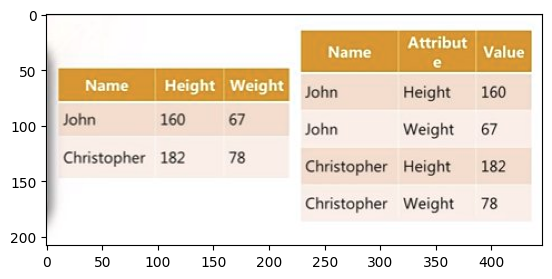

'\nWide format is where we have a single row for every data point with multiple columns to hold the values of various attributes.\n\nLong format is where, for each data point we have as many rows as the number of attributes and each row contains the value of a particular \nattribute for a given data point\n'

In [21]:
# Long Vs Wide Data
img2 =cv2.imread(r"C:\Users\prana\OneDrive\Pictures\Screenshots\Screenshot 2026-07-14 224942.png") 
plt.imshow(img2)
plt.show()
'''
Wide format is where we have a single row for every data point with multiple columns to hold the values of various attributes.

Long format is where, for each data point we have as many rows as the number of attributes and each row contains the value of a particular 
attribute for a given data point
'''

In [22]:
# melt -> simple example branch
# wide to long convert krta hai melt
print(pd.DataFrame({'cse':[120]}))
pd.DataFrame({'cse':[120]}).melt()

   cse
0  120


,variable,value
0,cse,120


In [23]:
# melt -> branch with year
print(pd.DataFrame({'cse':[120],'ece':[100],'mech':[50]}))
pd.DataFrame({'cse':[120],'ece':[100],'mech':[50]}).melt(var_name='branch',value_name='num_students')


   cse  ece  mech
0  120  100    50


,branch,num_students
0,cse,120
1,ece,100
2,mech,50


In [24]:
data_frame4 = pd.DataFrame(
    {
        'branch':['cse','ece','mech'],
        '2020':[100,150,60],
        '2021':[120,130,80],
        '2022':[150,140,70]
    }
)
print(data_frame4)
data_frame4.melt() # ish jagah hma "branch" koa row nhi bna na tha..
# so we have to do:-
data_frame4.melt(id_vars=['branch'],var_name='year',value_name='students')



  branch  2020  2021  2022
0    cse   100   120   150
1    ece   150   130   140
2   mech    60    80    70


,branch,year,students
0,cse,2020,100
1,ece,2020,150
2,mech,2020,60
3,cse,2021,120
4,ece,2021,130
5,mech,2021,80
6,cse,2022,150
7,ece,2022,140
8,mech,2022,70


In [25]:
death = pd.read_csv(r"D:\Coding Language\Python\DataSet\MergingJoining\time_series_covid19_deaths_global.csv")
confirm=pd.read_csv(r"D:\Coding Language\Python\DataSet\MergingJoining\time_series_covid19_confirmed_global.csv")
print(death.head())
print(confirm.head())

  Province/State Country/Region       Lat       Long  1/22/20  1/23/20  \
0            NaN    Afghanistan  33.93911  67.709953        0        0   
1            NaN        Albania  41.15330  20.168300        0        0   
2            NaN        Algeria  28.03390   1.659600        0        0   
3            NaN        Andorra  42.50630   1.521800        0        0   
4            NaN         Angola -11.20270  17.873900        0        0   

   1/24/20  1/25/20  1/26/20  1/27/20  ...  12/24/22  12/25/22  12/26/22  \
0        0        0        0        0  ...      7845      7846      7846   
1        0        0        0        0  ...      3595      3595      3595   
2        0        0        0        0  ...      6881      6881      6881   
3        0        0        0        0  ...       165       165       165   
4        0        0        0        0  ...      1928      1928      1928   

   12/27/22  12/28/22  12/29/22  12/30/22  12/31/22  1/1/23  1/2/23  
0      7846      7846      7

In [26]:
# Convert death and confirm dataset into long format 
death = death.melt(id_vars=['Province/State','Country/Region','Lat','Long'],var_name='date',value_name='num_deaths')
confirm = confirm.melt(id_vars=['Province/State','Country/Region','Lat','Long'],var_name='date',value_name='num_cases')
print(confirm)
print()
print(death)

       Province/State        Country/Region        Lat        Long     date  \
0                 NaN           Afghanistan  33.939110   67.709953  1/22/20   
1                 NaN               Albania  41.153300   20.168300  1/22/20   
2                 NaN               Algeria  28.033900    1.659600  1/22/20   
3                 NaN               Andorra  42.506300    1.521800  1/22/20   
4                 NaN                Angola -11.202700   17.873900  1/22/20   
...               ...                   ...        ...         ...      ...   
311248            NaN    West Bank and Gaza  31.952200   35.233200   1/2/23   
311249            NaN  Winter Olympics 2022  39.904200  116.407400   1/2/23   
311250            NaN                 Yemen  15.552727   48.516388   1/2/23   
311251            NaN                Zambia -13.133897   27.849332   1/2/23   
311252            NaN              Zimbabwe -19.015438   29.154857   1/2/23   

        num_cases  
0               0  
1          

In [ ]:
# apply filter and only specific columns
confirm.merge(death,on=['Province/State','Country/Region','Lat','Long','date'])[['Country/Region','date','num_cases','num_deaths']]

,Country/Region,date,num_cases,num_deaths
0,Afghanistan,1/22/20,0,0
1,Albania,1/22/20,0,0
2,Algeria,1/22/20,0,0
3,Andorra,1/22/20,0,0
4,Angola,1/22/20,0,0
...,...,...,...,...
311248,West Bank and Gaza,1/2/23,703228,5708
311249,Winter Olympics 2022,1/2/23,535,0
311250,Yemen,1/2/23,11945,2159
311251,Zambia,1/2/23,334661,4024
